# Movie Review Sentiment Classification

Classifies 50,000 IMDB movie reviews as positive or negative and compares three approaches:

1. **VADER**, a rule-based sentiment lexicon with no training
2. **Naive Bayes** on word counts
3. **Logistic regression and linear SVM** on TF-IDF features (single words, then word pairs)

Then it looks inside the best model: which words carry the most weight, and what kinds of review it gets wrong.

In [1]:
import re, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Data

In [2]:
URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
LOCAL = Path("IMDB-Dataset.csv")
if not LOCAL.exists():
    urlretrieve(URL, LOCAL)   # about 66 MB
df = pd.read_csv(LOCAL)
print(df.shape, "| duplicates:", df["review"].duplicated().sum())
df = df.drop_duplicates("review").reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)
df["sentiment"].value_counts()

(50000, 2) | duplicates: 418


sentiment
positive    24884
negative    24698
Name: count, dtype: int64

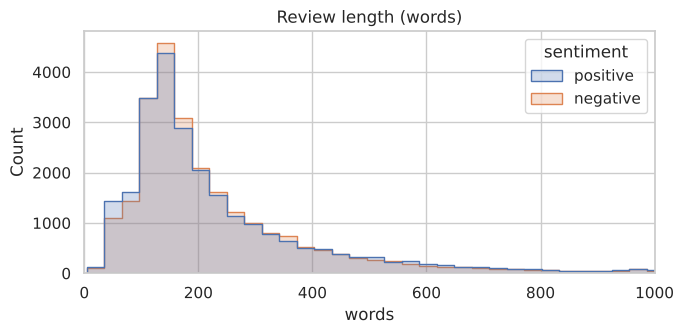

sentiment
negative    173.0
positive    171.0
Name: words, dtype: float64

In [3]:
def clean(text):
    text = re.sub(r"<br\s*/?>", " ", text)      # HTML line breaks
    return re.sub(r"\s+", " ", text).strip()
df["text"] = df["review"].map(clean)
df["words"] = df["text"].str.split().str.len()
plt.figure(figsize=(7, 3.5))
ax = sns.histplot(data=df, x="words", hue="sentiment", bins=80, element="step")
ax.set_xlim(0, 1000); ax.set_title("Review length (words)")
plt.tight_layout(); plt.savefig("images/review_length.png", dpi=120); plt.show()
df.groupby("sentiment")["words"].median()

Classes are balanced and reviews are long (median about 175 words). Length alone tells us nothing about sentiment.

In [4]:
train, test = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)
len(train), len(test)

(39665, 9917)

## 2. Baseline with no training: VADER

In [5]:
vader = SentimentIntensityAnalyzer()
test = test.copy()
test["vader"] = test["text"].map(lambda t: vader.polarity_scores(t)["compound"])
vader_pred = (test["vader"] >= 0).astype(int)
results = [{"model": "VADER (lexicon, no training)", "accuracy": accuracy_score(test["label"], vader_pred),
            "F1": f1_score(test["label"], vader_pred)}]
results[0]

{'model': 'VADER (lexicon, no training)',
 'accuracy': 0.697388323081577,
 'F1': 0.7404203788599603}

## 3. Trained models

In [6]:
models = {
    "Naive Bayes (word counts)": make_pipeline(CountVectorizer(min_df=3, stop_words="english"), MultinomialNB()),
    "Logistic regression (TF-IDF, words)": make_pipeline(
        TfidfVectorizer(min_df=3, sublinear_tf=True), LogisticRegression(C=4, max_iter=2000)),
    "Logistic regression (TF-IDF, words + pairs)": make_pipeline(
        TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True, max_features=300_000),
        LogisticRegression(C=8, max_iter=2000)),
    "Linear SVM (TF-IDF, words + pairs)": make_pipeline(
        TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True, max_features=300_000),
        LinearSVC(C=0.5)),
}
preds = {}
for name, m in models.items():
    m.fit(train["text"], train["label"])
    preds[name] = m.predict(test["text"])
    results.append({"model": name, "accuracy": accuracy_score(test["label"], preds[name]),
                    "F1": f1_score(test["label"], preds[name])})
res = pd.DataFrame(results).set_index("model").round(4)
res

,accuracy,F1
model,,
"VADER (lexicon, no training)",0.6974,0.7404
Naive Bayes (word counts),0.8544,0.8512
"Logistic regression (TF-IDF, words)",0.9005,0.9016
"Logistic regression (TF-IDF, words + pairs)",0.9160,0.9171
"Linear SVM (TF-IDF, words + pairs)",0.9162,0.9173


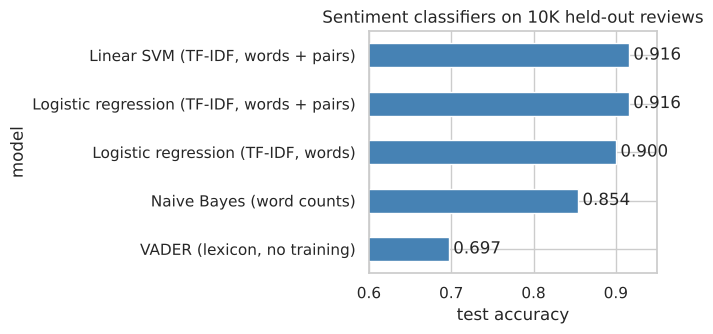

In [7]:
ax = res["accuracy"].sort_values().plot.barh(figsize=(7, 3.5), color="steelblue")
ax.set_xlim(0.6, 0.95); ax.set_xlabel("test accuracy"); ax.set_title("Sentiment classifiers on 10K held-out reviews")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", padding=3)
plt.tight_layout(); plt.savefig("images/model_comparison.png", dpi=120); plt.show()

Training on labeled reviews beats the general-purpose lexicon by a wide margin. Adding word pairs (bigrams) helps because they capture phrases like "not good", "waste of" and "highly recommend" that single words miss.

## 4. Inside the best model

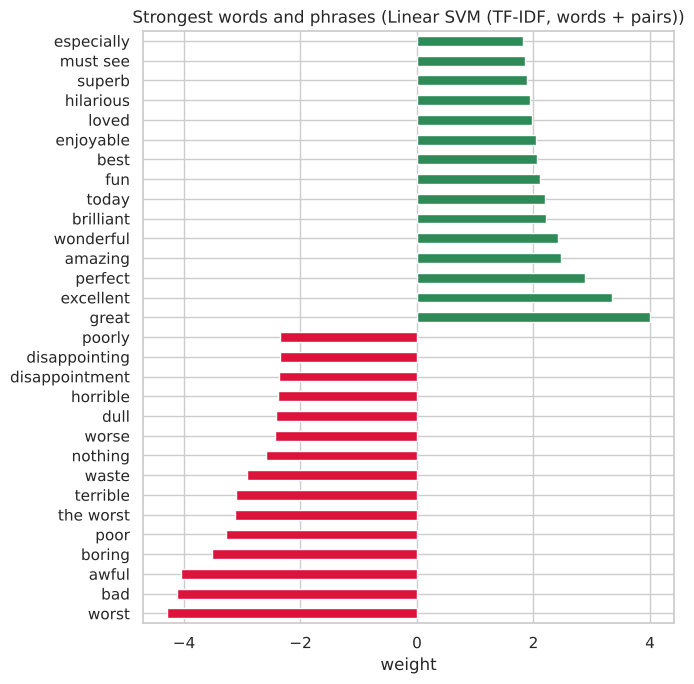

In [8]:
best_name = res["accuracy"].idxmax()
best = models[best_name]
vec, clf = best.steps[0][1], best.steps[1][1]
coefs = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())
top = pd.concat([coefs.nsmallest(15), coefs.nlargest(15)])
plt.figure(figsize=(7, 7))
top.plot.barh(color=["crimson"] * 15 + ["seagreen"] * 15)
plt.title(f"Strongest words and phrases ({best_name})"); plt.xlabel("weight")
plt.tight_layout(); plt.savefig("images/top_features.png", dpi=120); plt.show()

In [9]:
cm = confusion_matrix(test["label"], preds[best_name])
print(classification_report(test["label"], preds[best_name], target_names=["negative", "positive"], digits=3))

              precision    recall  f1-score   support

    negative      0.924     0.907     0.915      4940
    positive      0.909     0.926     0.917      4977

    accuracy                          0.916      9917
   macro avg      0.916     0.916     0.916      9917
weighted avg      0.916     0.916     0.916      9917



## 5. Error analysis

In [10]:
test["pred"] = preds[best_name]
test["margin"] = best.decision_function(test["text"])
wrong = test[test["pred"] != test["label"]].copy()
print(f"{len(wrong)} errors out of {len(test)}")
print("median length, errors vs all:", wrong["words"].median(), "vs", test["words"].median())
# Most confident mistakes
for _, r in wrong.reindex(wrong["margin"].abs().sort_values(ascending=False).index).head(4).iterrows():
    print(f"\n[true: {r['sentiment']}, margin {r['margin']:.2f}] {r['text'][:350]}...")

831 errors out of 9917
median length, errors vs all: 172.0 vs 170.0

[true: negative, margin 1.42] this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gentle and she loves her...

[true: positive, margin -1.37] "Comanche Moon" had everything going for it. For starters, Simon Wincer's back, a man who's name is synonymous with high-quality TV westerns. Unfortunately, the problems with "Moon" are something even the most talented director couldn't solve: A poor script based on a lackluster novel. Forget historical accuracies -- as any reader of the novels can...

[true: negative, margin 1.28] When i finally had the opportunity to watch Zombie 3(Zombie Flesheaters 2 in Europe)on an import Region 2 Japanese dvd,i was blown

In [11]:
# Reviews where the overall verdict contradicts much of the wording: mixed or sarcastic
test["has_but"] = test["text"].str.contains(r"\bbut\b|\bhowever\b", case=False)
test.groupby("has_but").apply(lambda g: (g["pred"] != g["label"]).mean()).rename("error rate").to_frame()

,error rate
has_but,
False,0.059233
True,0.092446


## Takeaways

- A linear SVM on TF-IDF words and word pairs reaches 91.6% accuracy on 9,917 held-out reviews, 22 points above the VADER lexicon (69.7%). Logistic regression with the same features scores the same.
- Word pairs add 1.6 points over single words, because phrases like "the worst" and "must see" carry meaning that single words lose.
- The strongest signals are easy to explain ("worst", "bad", "awful" against "great", "excellent", "perfect"), so the model can be audited.
- Errors are not about length. They are more common in mixed reviews: 9.2% of reviews containing "but" or "however" are misclassified, against 5.9% of the rest.
- Several of the model's most confident mistakes read as clearly positive reviews labeled negative (or the reverse). Some "errors" are label noise in the dataset, which puts a ceiling on any model's measured accuracy.
- Next step: fine-tune a transformer such as DistilBERT, which reads word order and context, and check whether its gain justifies the extra compute.